# Actividad 6 | Evaluación y validación de modelos de clasificación bancaria

**Origen:** resultados verificables de la Actividad 5. Se comparan Regresión Logística y Multinomial Naive Bayes en 77 intenciones.

**Objetivo SMART:** evaluar ambos modelos sobre el conjunto de prueba, contrastar F1 macro con la meta de 0.90, estudiar cobertura y errores según umbral de confianza, y documentar una propuesta de prueba A/B operativa.

> Nota metodológica: un análisis retrospectivo de predicciones no es una prueba A/B desplegada. La curva ROC/AUC multiclase ya fue calculada en la Actividad 5 y se reporta como resultado histórico; para reconstruir la curva completa se requieren las probabilidades por clase o volver a ejecutar los modelos.

## 1. Cargar resultados


In [1]:
import io, zipfile, pathlib, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score
from statsmodels.stats.contingency_tables import mcnemar
zip_path = pathlib.Path('Actividad5_ejecutada.zip')
if not zip_path.exists():
    from google.colab import files
    files.upload()
assert zip_path.exists(), 'Sube Actividad5_ejecutada.zip'
z = zipfile.ZipFile(zip_path)
root = 'Actividad5/resultados/'
def csv(name): return pd.read_csv(io.BytesIO(z.read(root + name)))
def js(name): return json.loads(z.read(root + name).decode('utf-8'))
metrics = csv('metricas.csv')
log = csv('predicciones_Regresion_logistica.csv')
nb = csv('predicciones_Multinomial_NB.csv')
print('Muestras:', len(log), 'Clases:', log.category.nunique())
display(metrics)


Saving Actividad5_ejecutada.zip to Actividad5_ejecutada.zip
Muestras: 3079 Clases: 77


,modelo,cv_f1_macro,cv_f1_std,busqueda_segundos,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro
0,Regresion_logistica,0.882391,0.005681,120.976861,0.900617,0.904932,0.900633,0.900783,0.998050
1,Multinomial_NB,0.839078,0.012154,14.565119,0.856772,0.865434,0.856793,0.855759,0.997335


## 2. Métricas y comparación con baseline

Baseline registrado: {'accuracy': 0.012991230919129588, 'f1_macro': 0.00033310709809587655, 'regla': 'clase_mayoritaria_train'}


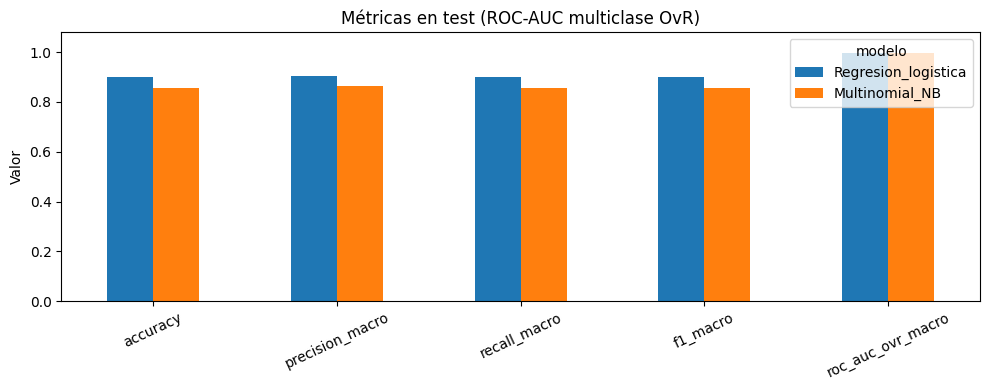

Meta F1 macro >= 0.90: {'Regresion_logistica': True, 'Multinomial_NB': False}


In [2]:
baseline = js('baseline.json')
print('Baseline registrado:', baseline)
cols = ['accuracy','precision_macro','recall_macro','f1_macro','roc_auc_ovr_macro']
ax = metrics.set_index('modelo')[cols].T.plot(kind='bar', figsize=(10,4), ylim=(0,1.08), rot=25)
ax.set_ylabel('Valor'); ax.set_title('Métricas en test (ROC-AUC multiclase OvR)')
plt.tight_layout(); plt.show()
print('Meta F1 macro >= 0.90:', dict(zip(metrics.modelo,metrics.f1_macro >= .90)))


## 3. Matriz de confusión y errores frecuentes
La matriz de 77 × 77 se resume visualmente para evitar etiquetas ilegibles; se identifican confusiones específicas.

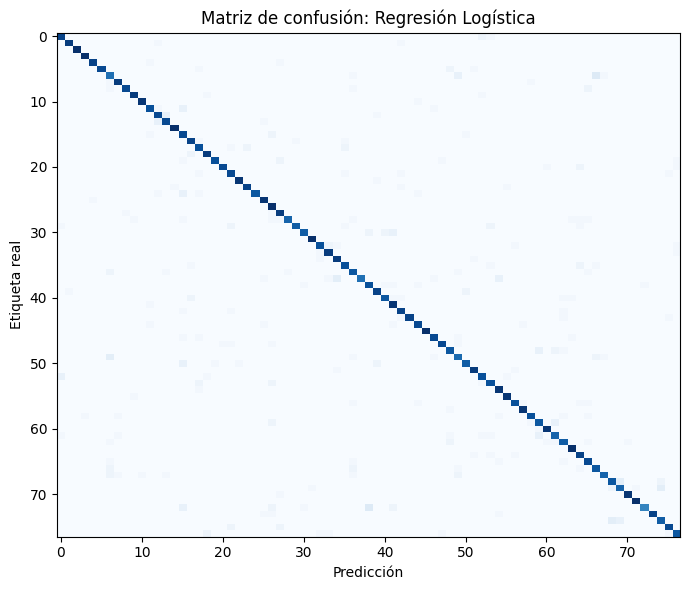

Regresión Logística Errores: 306


,category,prediccion,casos
0,balance_not_updated_after_bank_transfer,transfer_not_received_by_recipient,5
1,virtual_card_not_working,get_disposable_virtual_card,5
2,fiat_currency_support,exchange_via_app,4
3,pending_transfer,balance_not_updated_after_bank_transfer,4
4,unable_to_verify_identity,verify_my_identity,4
5,verify_my_identity,why_verify_identity,4
6,why_verify_identity,unable_to_verify_identity,4
7,card_acceptance,card_not_working,3
8,card_arrival,card_delivery_estimate,3
9,card_delivery_estimate,card_arrival,3


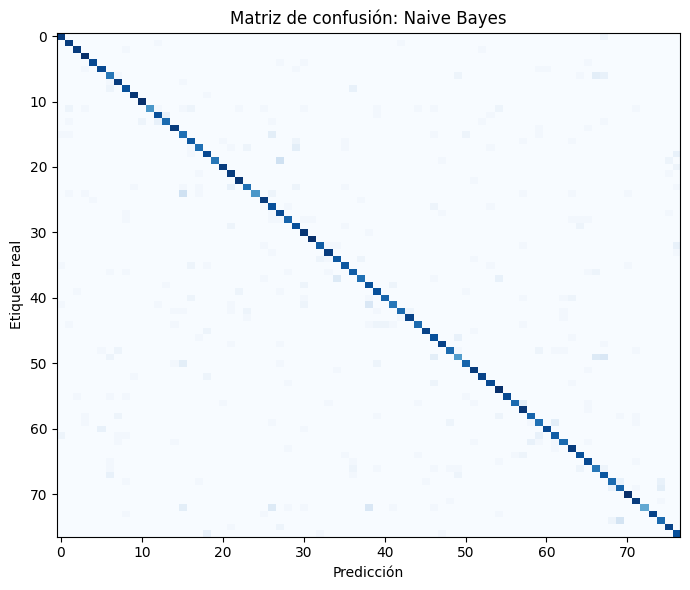

Naive Bayes Errores: 441


,category,prediccion,casos
0,card_swallowed,declined_cash_withdrawal,8
1,contactless_not_working,card_not_working,8
2,why_verify_identity,verify_my_identity,7
3,virtual_card_not_working,get_disposable_virtual_card,6
4,pending_transfer,transfer_timing,6
5,getting_virtual_card,get_disposable_virtual_card,6
6,fiat_currency_support,exchange_via_app,5
7,pending_transfer,transfer_not_received_by_recipient,5
8,virtual_card_not_working,declined_card_payment,5
9,top_up_failed,top_up_reverted,4


In [3]:
for name, df in [('Regresión Logística',log),('Naive Bayes',nb)]:
    labels = sorted(df.category.unique())
    cm = confusion_matrix(df.category, df.prediccion, labels=labels)
    fig,ax=plt.subplots(figsize=(7,6)); ax.imshow(cm,aspect='auto',cmap='Blues')
    ax.set(title='Matriz de confusión: '+name,xlabel='Predicción',ylabel='Etiqueta real')
    plt.tight_layout();plt.show()
    errs=(df.loc[df.category != df.prediccion].groupby(['category','prediccion']).size().sort_values(ascending=False).head(10))
    print(name,'Errores:',int((df.category!=df.prediccion).sum())); display(errs.rename('casos').reset_index())


## 4. Umbrales de confianza y derivación a revisión humana
`score_maximo` es la confianza de la clase elegida. Se evalúa una **política de abstención**: aceptar automáticamente predicciones con confianza ≥ umbral; enviar el resto a revisión. La precisión de los casos aceptados no es una métrica de clasificación binaria estándar.

,modelo,umbral,cobertura,exactitud_aceptados,a_revision,errores_automaticos
0,Regresión Logística,0.0,1.000000,0.900617,0,306
1,Regresión Logística,0.3,0.942839,0.928694,176,207
2,Regresión Logística,0.5,0.838909,0.962834,496,96
3,Regresión Logística,0.7,0.693407,0.981733,944,39
4,Regresión Logística,0.8,0.601819,0.989746,1226,19
5,Regresión Logística,0.9,0.435531,0.993289,1738,9
6,Naive Bayes,0.0,1.000000,0.856772,0,441
7,Naive Bayes,0.3,0.833063,0.928655,514,183
8,Naive Bayes,0.5,0.635921,0.975996,1121,47
9,Naive Bayes,0.7,0.413771,0.995290,1805,6


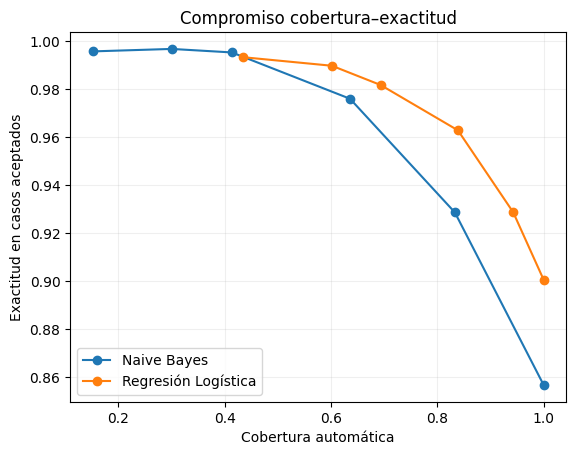

In [4]:
rows=[]
for name,df in [('Regresión Logística',log),('Naive Bayes',nb)]:
    for t in [0.0,0.3,0.5,0.7,0.8,0.9]:
        accepted=df.score_maximo>=t
        rows.append({'modelo':name,'umbral':t,'cobertura':accepted.mean(),
                     'exactitud_aceptados':df.loc[accepted,'correcto'].mean() if accepted.any() else np.nan,
                     'a_revision':int((~accepted).sum()),'errores_automaticos':int((accepted & ~df.correcto.astype(bool)).sum())})
thresholds=pd.DataFrame(rows); display(thresholds)
for name,g in thresholds.groupby('modelo'):
    plt.plot(g.cobertura,g.exactitud_aceptados,marker='o',label=name)
plt.xlabel('Cobertura automática');plt.ylabel('Exactitud en casos aceptados');plt.title('Compromiso cobertura–exactitud');plt.legend();plt.grid(alpha=.2);plt.show()


## 5. Validación cruzada de cinco particiones

In [5]:
cv=metrics[['modelo','cv_f1_macro','cv_f1_std','f1_macro']].copy()
cv['brecha_test_menos_cv']=cv.f1_macro-cv.cv_f1_macro
display(cv)
print('La desviación CV resume variabilidad entre folds; no es por sí sola un intervalo de confianza.')


,modelo,cv_f1_macro,cv_f1_std,f1_macro,brecha_test_menos_cv
0,Regresion_logistica,0.882391,0.005681,0.900783,0.018392
1,Multinomial_NB,0.839078,0.012154,0.855759,0.016681


La desviación CV resume variabilidad entre folds; no es por sí sola un intervalo de confianza.


## 6. Comparación pareada y significancia
McNemar compara aciertos y errores de ambos modelos sobre **las mismas observaciones**. No equivale a una prueba A/B con usuarios asignados aleatoriamente.

In [6]:
paired=log[['id','category','correcto']].merge(nb[['id','category','correcto']],on=['id','category'],suffixes=('_lr','_nb'),validate='one_to_one')
a=paired.correcto_lr.astype(bool);b=paired.correcto_nb.astype(bool)
table=np.array([[int((~a&~b).sum()),int((~a&b).sum())],[int((a&~b).sum()),int((a&b).sum())]])
print('Filas: LR falla/acierta; columnas: NB falla/acierta')
print(table)
r=mcnemar(table,exact=False,correction=True)
print('McNemar p:',r.pvalue)
print('Interpretación:', 'evidencia de diferencia en tasa de aciertos' if r.pvalue<.05 else 'evidencia insuficiente de diferencia')


Filas: LR falla/acierta; columnas: NB falla/acierta
[[ 240   66]
 [ 201 2572]]
McNemar p: 2.39057241585135e-16
Interpretación: evidencia de diferencia en tasa de aciertos


## 7. Prueba A/B propuesta (NO ejecutada)
**Hipótesis:** en tráfico bancario real, Regresión Logística reduce las derivaciones incorrectas frente a Naive Bayes. **Unidad de aleatorización:** conversación/usuario según control de contaminación. **A:** Naive Bayes; **B:** Regresión Logística. **Métrica primaria:** proporción de intenciones correctamente enrutadas según revisión humana independiente. **Guardrails:** latencia, tasa de revisión, quejas y tasa de fallos críticos. **Diseño:** asignación aleatoria, tamaño de muestra y duración predefinidos, monitoreo de sesgos y consentimiento/privacidad aplicables. **Análisis:** contraste de dos proporciones con intervalo de confianza; ajustar por múltiples pruebas si procede. No se reportan resultados ficticios de un experimento en producción.

## 8. Conclusiones y trazabilidad
Los resultados muestran que Regresión Logística presenta un mejor desempeño que Naive Bayes en la clasificación de las 77 intenciones bancarias, alcanzando un F1-score macro de 90.08%.
La validación cruzada y la prueba de McNemar respaldan su selección como modelo principal. Asimismo, el análisis de umbrales evidencia que es posible reducir los errores de clasificación automática mediante un esquema de revisión humana.
Como siguiente etapa, se propone validar su desempeño en un entorno operativo mediante una prueba A/B controlada.


In [7]:
print(metrics[['modelo','f1_macro','roc_auc_ovr_macro']].to_string(index=False))
print('Comparación estadística histórica:'); print(js('comparacion_estadistica.json'))


             modelo  f1_macro  roc_auc_ovr_macro
Regresion_logistica  0.900783           0.998050
     Multinomial_NB  0.855759           0.997335
Comparación estadística histórica:
{'modelo_A': 'Regresion_logistica', 'modelo_B': 'Multinomial_NB', 'seleccionado_por_CV': 'Regresion_logistica', 'solo_A_acierta': 201, 'solo_B_acierta': 66, 'mcnemar_exacto_p': 4.9460565388946843e-17, 'diferencia_accuracy_A_menos_B': 0.0438454043520623, 'IC95_bootstrap_pareado_estratificado_accuracy': [0.03312763884378045, 0.054238389087366], 'bootstrap_replicas': 1000, 'limite': 'Comparación de aciertos en un test fijo; no demuestra rendimiento en español ni en producción. La dispersión CV no es un intervalo de confianza independiente.'}
